## Developing a better forecast of returns 15:50 - 16:00pm

### Collecting Data

In [1]:
from data_collection.data_adapters import DatabentoGenericAdapter
from dotenv import load_dotenv
from pathlib import Path
import os
import polars as pl
import numpy as np
import matplotlib.pyplot as plt
load_dotenv()
pl.enable_string_cache()

CACHE_DIR = Path.cwd().resolve().parents[0] / "data" / "dbn_cache" / "generic"
adapter = DatabentoGenericAdapter(os.getenv("DATABENTO-API-KEY"), CACHE_DIR)

print(f"CACHE_DIR: {CACHE_DIR}")
# Clear the cache if needed
# adapter.clear_cache()

with open("../universe.txt", "r") as f:
    UNIVERSE = [line.strip() for line in f]
with open("../top_50_universe.txt", "r") as f:
    ACTIVE_SET = [line.strip() for line in f]
START = "2025-06-11"
END = "2026-06-11"
DATASET = "XNAS.ITCH"

# Imbalance
df_imbalance = (
    adapter.scan_data(
        tickers=UNIVERSE,
        start_date=START,
        end_date=END,
        dataset=DATASET,
        schema="imbalance"
    )
    .select(["ts_event", "symbol", "side", "total_imbalance_qty", "paired_qty", "ref_price"])
    .with_columns(
        pl.col('ts_event').dt.convert_time_zone("America/New_York"),
        pl.col("symbol").cast(pl.Categorical)
    )
    .filter(pl.col('ts_event').dt.time().is_between(pl.time(9,30), pl.time(16,00)),
            pl.col("symbol").is_in(ACTIVE_SET))
)

# trades with the bbo
df_trades = (
    adapter.scan_data(
        tickers=UNIVERSE,
        start_date=START,
        end_date=END,
        dataset=DATASET,
        schema="tbbo"
    )
    .select(["ts_event", "symbol", "price", "size", "ask_px_00", "bid_px_00"])
    .filter(pl.col('ts_event').dt.time().is_between(pl.time(13,30), pl.time(21,0)),
            pl.col("symbol").is_in(ACTIVE_SET))
    .with_columns(pl.col('ts_event').dt.convert_time_zone("America/New_York"))
    .filter(pl.col('ts_event').dt.time().is_between(pl.time(9,30), pl.time(16,00)))
    .with_columns(pl.col("symbol").cast(pl.Categorical))
)

# statistics (for the official closing auction price)
df_stats = (
    adapter.scan_data(
        tickers=UNIVERSE,
        start_date=START,
        end_date=END,
        dataset=DATASET,
        schema="statistics"
    )
    .select(["ts_event", "stat_type", "symbol", "price", "quantity"])
    .with_columns(
        pl.col('ts_event').dt.convert_time_zone("America/New_York"),
        pl.col("symbol").cast(pl.Categorical)
    )
    .filter(pl.col("stat_type") == 11,
            pl.col("symbol").is_in(ACTIVE_SET))
)


CACHE_DIR: /Users/michaelcusack-nelkin/GitHub/Summer_Research_2026/data/dbn_cache/generic
[GenericAdapter] scan_parquet: 015b0f098e17be916bbb238312a4d5d4.parquet
[GenericAdapter] scan_parquet: 6436dd54a7ced32262a3242e08d42d20.parquet
[GenericAdapter] scan_parquet: 83ab27f48711d5689292fe953cab702b.parquet


In [2]:
avg_daily_dollar_volume = (
    df_trades
    .select((["ts_event", "symbol", "price", "size"]))
    .with_columns(pl.col("ts_event").dt.date().alias("date"))
    .filter(pl.col('ts_event').dt.time().is_between(pl.time(9,30), pl.time(16,00)))
    .group_by(["date", "symbol"])
    .agg(
    (pl.col('size') * pl.col("price")).sum().alias("day_volume")
    )
    .sort(["date", "symbol"])
    .with_columns(
    pl.col("day_volume").ewm_mean(span=10, adjust=True).shift(1).over("symbol", order_by="date").alias("ADV")
    )
    .drop("day_volume")
    .collect(engine="streaming")
)

auction = (
    df_stats
    .with_columns(
        pl.col("ts_event").dt.date().alias("date")
    )
    .select("date", "symbol", "price")
    .rename({"price": "auction_price"})
    .collect(engine="streaming")
)

close_trades = (
    df_trades
    .with_columns(
        pl.col("ts_event").dt.date().alias("date"),
        ((pl.col("ask_px_00") - pl.col("bid_px_00")) / ((pl.col("ask_px_00") + pl.col("bid_px_00")) / 2)).alias("spread_return"),
        ((pl.col("ask_px_00") + pl.col("bid_px_00")) / 2).alias("mid")
    )
    .filter(pl.col("ts_event").dt.time().is_between(pl.time(15,45,00), pl.time(15,50,00)))          
    .group_by(["date", "symbol"], maintain_order=True)
    .agg(
        pl.col(["mid", "spread_return"]).last()
    )
    .rename({"mid":"entry_price"})
    .collect(engine="streaming")
)

recent_return = (
    df_trades
    .with_columns(pl.col("ts_event").dt.date().alias("date"),
                  ((pl.col("ask_px_00") + pl.col("bid_px_00")) / 2).alias("mid"))
    .filter(pl.col("ts_event").dt.time().is_between(pl.time(15,45,00), pl.time(15,50,00)))          
    .group_by(["date", "symbol"], maintain_order=True)
    .agg(
        (pl.col("mid").last() - pl.col("mid").first())/pl.col("mid").first()
    )
    .rename({"mid":"recent_return"})
    .collect(engine="streaming")
)

imb_print = (
    df_imbalance
    .filter(pl.col("ts_event").dt.time() >= pl.time(15,50))
    .with_columns(pl.col("ts_event").dt.date().alias("date"))
    .group_by(["date", "symbol"], maintain_order=True)
    .agg(
        pl.col(["side", "total_imbalance_qty", "paired_qty", "ref_price"]).first()
    )
    .collect(engine="streaming")
)

In [3]:
data = (
    imb_print
    .join(close_trades, on=["date", "symbol"])
    .join(auction, on=["date", "symbol"])
    .join(avg_daily_dollar_volume, on=["date", "symbol"])
    .join(recent_return, on=["date", "symbol"])
    .sort(["date", "symbol"])
    .with_columns(
        (pl.col("total_imbalance_qty") * pl.col("ref_price")).alias("dollar_imbalance"),
        (pl.col("paired_qty") * pl.col("ref_price")).alias("paired_dollars"),
        (
            pl.when(pl.col("side") == "B").then(1)
            .when(pl.col("side") == "A").then(-1)
            .when(pl.col("side") == "N").then(0)
        ).alias("sign"),
    )
    .with_columns(
        (
            pl.col("sign") * pl.col("dollar_imbalance")
        ).alias("signed_dollar_imbalance")
    )
    .drop(["total_imbalance_qty"])
    .drop_nulls()
    .with_columns(
        (
            (pl.col("paired_dollars") / pl.col("ADV"))
        ).alias("auction_dollar_volume_ratio"),
        (
            pl.when(pl.col("paired_dollars") != 0).then(pl.col("signed_dollar_imbalance") / pl.col("paired_dollars"))
            .otherwise(0)
        ).alias("net_signed_imb"),
        (
            (pl.col("auction_price") - pl.col("entry_price")) / pl.col("entry_price")
        ).alias("return_to_close")
    )
    .with_columns(
        (pl.col("return_to_close") - pl.col("return_to_close").mean().over("date")).alias("close_return_xm"),
        (pl.col("recent_return") - pl.col("recent_return").mean().over("date")).alias("recent_return_xm"),
        (pl.col("auction_dollar_volume_ratio") - pl.col("auction_dollar_volume_ratio").mean().over("date")).alias("auction_dollar_volume_ratio_xm"),
        (
            ((pl.col("net_signed_imb").rank().over(pl.col("date")) - pl.col("net_signed_imb").rank().min().over(pl.col("date"))) 
             / (pl.col("net_signed_imb").rank().max().over(pl.col("date")) - pl.col("net_signed_imb").rank().min().over(pl.col("date"))))
             * 2 - 1
        ).alias("norm_rank_net_imb"),
    )
    .with_columns(
        (pl.col("norm_rank_net_imb") * pl.col("recent_return_xm")).alias("norm_rank_net_x_recent_xm"),
        (pl.col("auction_dollar_volume_ratio_xm") * pl.col("norm_rank_net_imb")).alias("norm_rank_net_x_auction"),
        (pl.col("auction_dollar_volume_ratio_xm") * pl.col("recent_return_xm")).alias("auction_x_recent_xm")
    )
)

data.head()

date,symbol,side,paired_qty,ref_price,entry_price,spread_return,auction_price,ADV,recent_return,dollar_imbalance,paired_dollars,sign,signed_dollar_imbalance,auction_dollar_volume_ratio,net_signed_imb,return_to_close,close_return_xm,recent_return_xm,auction_dollar_volume_ratio_xm,norm_rank_net_imb,norm_rank_net_x_recent_xm,norm_rank_net_x_auction,auction_x_recent_xm
date,cat,str,u32,f64,f64,f64,f64,f64,f64,f64,f64,i32,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
2025-06-12,"""AAPL""","""A""",3154686,198.59,198.575,0.00005,199.2,2.2199e9,-0.000252,1.8048e8,6.2649e8,-1,-1.8048e8,0.282215,-0.288076,0.003147,0.001923,0.000247,0.072398,-0.291667,-0.000072,-0.021116,0.000018
2025-06-12,"""ABNB""","""A""",432809,138.81,138.82,0.000144,138.81,1.3647e8,0.000468,9.5236e6,6.0078e7,-1,-9.5236e6,0.440234,-0.15852,-0.000072,-0.001296,0.000967,0.230417,0.041667,0.00004,0.009601,0.000223
2025-06-12,"""ADBE""","""A""",146138,413.61,413.715,0.000314,413.68,2.5565e8,-0.000169,1.5911e7,6.0444e7,-1,-1.5911e7,0.236432,-0.263237,-0.000085,-0.001309,0.00033,0.026615,-0.208333,-0.000069,-0.005545,0.000009
2025-06-12,"""ADI""","""B""",100056,231.87,231.785,0.000388,232.12,1.4346e8,-0.000173,2.0391e7,2.3200e7,1,2.0391e7,0.161719,0.878908,0.001445,0.000221,0.000326,-0.048098,0.958333,0.000313,-0.046094,-0.000016
2025-06-12,"""AMAT""","""A""",210734,174.58,174.605,0.000286,175.0,2.2650e8,-0.00063,944303.22,3.6790e7,-1,-944303.22,0.162425,-0.025667,0.002262,0.001038,-0.000131,-0.047392,0.333333,-0.000044,-0.015797,0.000006


In [4]:
from scipy.stats import pearsonr
r, p = pearsonr(data['auction_dollar_volume_ratio_xm'], data['norm_rank_net_imb'])
r, p

(np.float64(-0.03546859028761688), np.float64(9.506525971811808e-05))

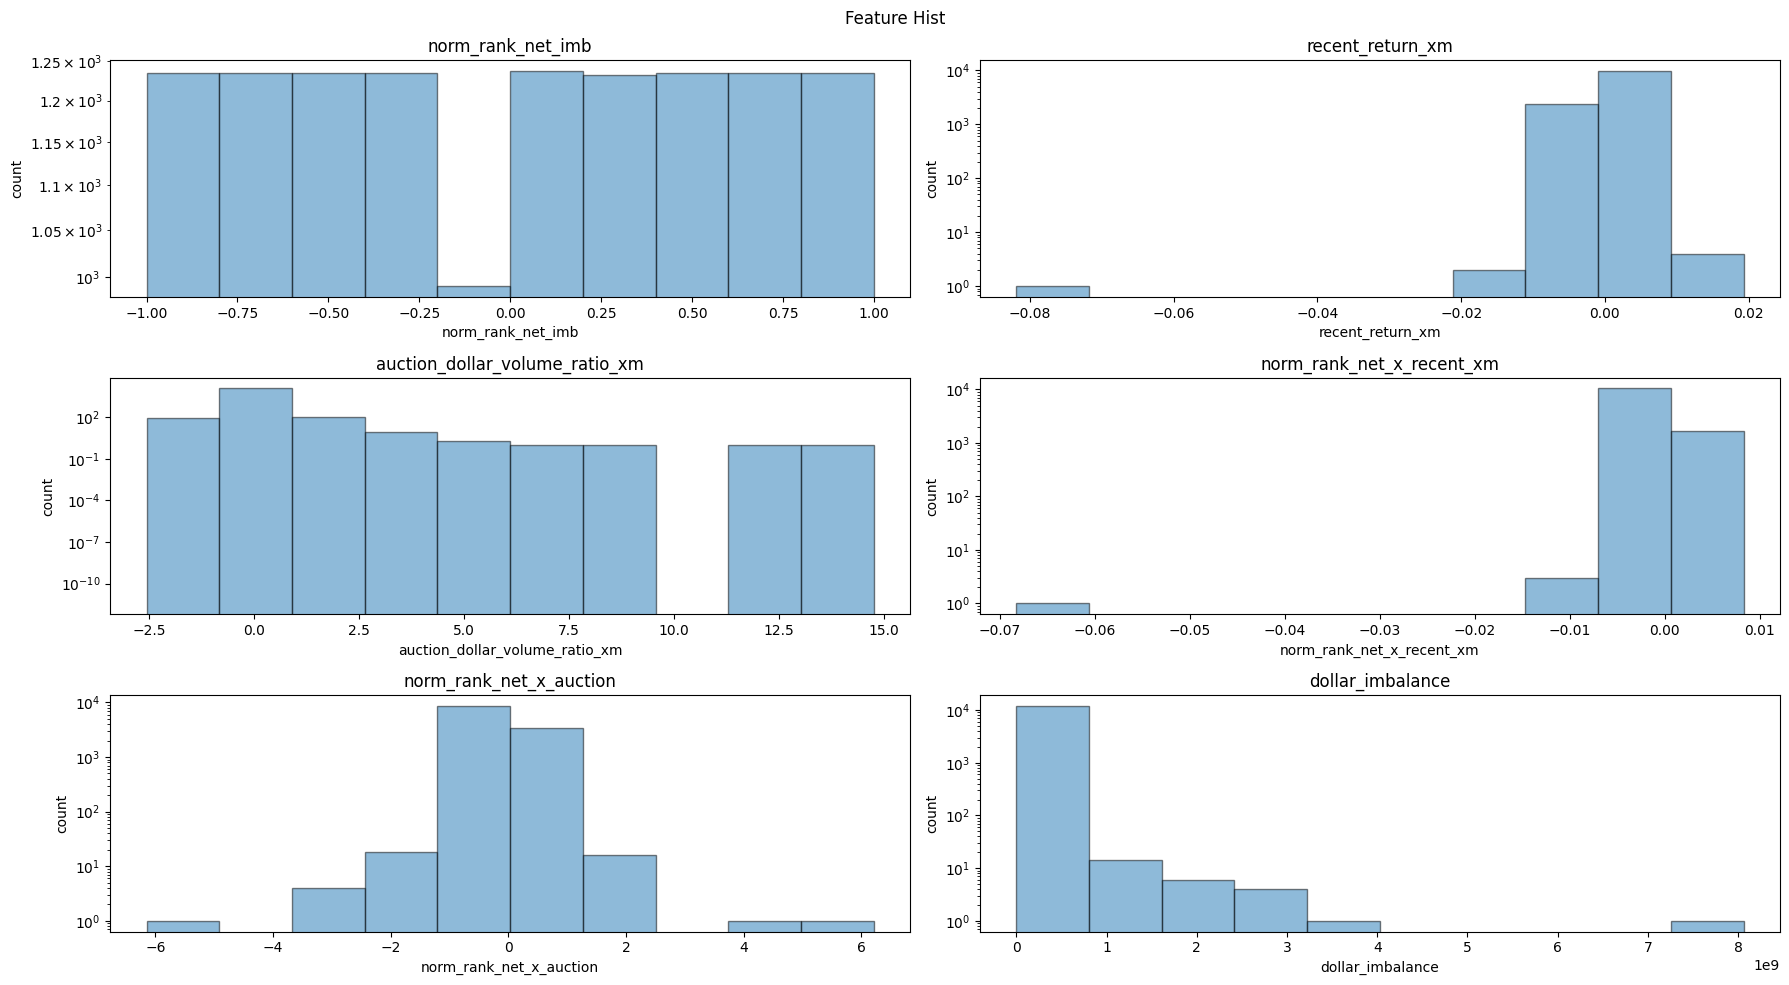

In [5]:
plot_features = [
    "norm_rank_net_imb", 
    "recent_return_xm",
    "auction_dollar_volume_ratio_xm",
    "norm_rank_net_x_recent_xm",
    "norm_rank_net_x_auction",
    "dollar_imbalance"
]
log_x = plot_features

fig, axes = plt.subplots(3, 2, figsize=(18, 10))
for ax, feat in zip(axes.flat, plot_features):
    x = data[feat].to_numpy()
    ax.hist(x, alpha=0.5, edgecolor="black")
    ax.axhline(0, color="grey", lw=0.5)
    if feat in log_x:
        # ax.set_xscale("log")
        ax.set_yscale("log")
    ax.set_xlabel(feat)
    ax.set_ylabel("count")
    ax.set_title(f"{feat}")

fig.suptitle("Feature Hist")
fig.tight_layout()
plt.show()

In [6]:
data.filter(pl.col("auction_dollar_volume_ratio") == pl.col("auction_dollar_volume_ratio").max())

date,symbol,side,paired_qty,ref_price,entry_price,spread_return,auction_price,ADV,recent_return,dollar_imbalance,paired_dollars,sign,signed_dollar_imbalance,auction_dollar_volume_ratio,net_signed_imb,return_to_close,close_return_xm,recent_return_xm,auction_dollar_volume_ratio_xm,norm_rank_net_imb,norm_rank_net_x_recent_xm,norm_rank_net_x_auction,auction_x_recent_xm
date,cat,str,u32,f64,f64,f64,f64,f64,f64,f64,f64,i32,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
2026-03-20,"""CMCSA""","""A""",77661417,29.27,29.265,0.000342,29.02,1.2968e8,-0.000342,1.4470e8,2.2731e9,-1,-1.4470e8,17.528317,-0.063657,-0.008372,-0.013331,0.00114,14.757802,-0.416667,-0.000475,-6.149084,0.016829


## Cross Validation

In [7]:
from sklearn.model_selection import TimeSeriesSplit
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Lasso, Ridge, LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, root_mean_squared_error
from scipy.stats import spearmanr
import statsmodels.api as sm


# Split on unique DATES (not rows): one day's cross-section must stay whole,
# otherwise the same date leaks across train/test.
dates = data["date"].unique().sort().to_list()
feature_sets = [
    [
        "norm_rank_net_imb", 
        "recent_return_xm", 
        "norm_rank_net_x_recent_xm",
    ],
    [
        "norm_rank_net_imb", 
        "auction_dollar_volume_ratio_xm",
        "norm_rank_net_x_auction",

    ],
    [
        "norm_rank_net_imb", 
        "recent_return_xm",
        "auction_dollar_volume_ratio_xm", 
        "norm_rank_net_x_recent_xm",
        "norm_rank_net_x_auction",
    ],
    [
        "norm_rank_net_imb", 
        "recent_return_xm", 
        "auction_dollar_volume_ratio_xm",
    ]
]
target = ["close_return_xm"]

tscv = TimeSeriesSplit(n_splits=49, max_train_size=90, test_size=5)  # rolling ~train window
scaler = StandardScaler()
fold_ics = []
fold_metrics = []
all_daily_ics = []
stds = []
for features in feature_sets:
    for i, (train_d, test_d) in enumerate(tscv.split(dates)):
        train_dates = [dates[j] for j in train_d]
        test_dates  = [dates[j] for j in test_d]

        train = data.filter(pl.col("date").is_in(train_dates))
        test  = data.filter(pl.col("date").is_in(test_dates))

        X_train_scale = scaler.fit_transform(train[features].to_numpy())
        y_train = train[target].to_numpy()
        X_test_scale = scaler.transform(test[features].to_numpy())
        y_test = test[target].to_numpy()

        model = Lasso(alpha=1e-4)
        model.fit(X_train_scale, y_train)

        # Forecast on test, then daily cross-sectional rank IC (Spearman), MSE, MAE, and R^2, averaged.
        pred = (
            test
            .with_columns(pl.Series("yhat", model.predict(X_test_scale)))
        )
        y_hat = pred['yhat'].to_numpy()
        daily_ic = (
            pred.group_by("date")
            .agg(
                pl.map_groups(
                    exprs=["yhat", target[0]],
                    function=lambda s: spearmanr(s[0], s[1]).statistic,
                    return_dtype=pl.Float64,
                    returns_scalar=True,
                ).alias("ic")
            )
            .drop_nulls()
        )
        mean_ic = daily_ic["ic"].mean()
        fold_ics.append(mean_ic)
        mse, mae, r2 = mean_squared_error(y_test, y_hat), mean_absolute_error(y_test, y_hat), model.score(X_test_scale, y_test)
        fold_metrics.append(
            (mse, mae, r2)
        )
        stds.append(np.std(y_hat) / np.std(y_test))
        all_daily_ics.extend(daily_ic["ic"].to_list())

    print(
        f"\n{features}"
        f"\nMean/Std IC across folds: {np.mean(fold_ics):+.4f}/{np.std(fold_ics):+.4f}"
        f"   (IR = {np.mean(fold_ics) / np.std(fold_ics):+.2f})"
        # f"\nMean Std(y_hat)/std(y_test): {np.mean(stds):+.6f}"
        f"\nMean R^2 across folds: {np.mean([r2 for (mse, mae, r2) in fold_metrics]):+.3f}"
        f"\nMean/Std MSE across folds: {np.mean([mse for (mse, mae, rmse) in fold_metrics]):+.3e}/{np.std([mse for (mse, mae, rmse) in fold_metrics]):+.3e}"
        f"   (t-stat = {np.mean([mse for (mse, mae, rmse) in fold_metrics]) / np.std([mse for (mse, mae, rmse) in fold_metrics]):+.2f})"
        # f"\nMean MAE across folds: {np.mean([mae for (mse, mae, rmse) in fold_metrics]):+.3e}"
        )


['norm_rank_net_imb', 'recent_return_xm', 'norm_rank_net_x_recent_xm']
Mean/Std IC across folds: +0.2434/+0.0835   (IR = +2.91)
Mean R^2 across folds: +0.056
Mean/Std MSE across folds: +9.624e-06/+6.605e-06   (t-stat = +1.46)

['norm_rank_net_imb', 'auction_dollar_volume_ratio_xm', 'norm_rank_net_x_auction']
Mean/Std IC across folds: +0.2459/+0.0812   (IR = +3.03)
Mean R^2 across folds: +0.056
Mean/Std MSE across folds: +9.650e-06/+6.691e-06   (t-stat = +1.44)

['norm_rank_net_imb', 'recent_return_xm', 'auction_dollar_volume_ratio_xm', 'norm_rank_net_x_recent_xm', 'norm_rank_net_x_auction']
Mean/Std IC across folds: +0.2426/+0.0807   (IR = +3.01)
Mean R^2 across folds: +0.054
Mean/Std MSE across folds: +9.662e-06/+6.682e-06   (t-stat = +1.45)

['norm_rank_net_imb', 'recent_return_xm', 'auction_dollar_volume_ratio_xm']
Mean/Std IC across folds: +0.2407/+0.0811   (IR = +2.97)
Mean R^2 across folds: +0.054
Mean/Std MSE across folds: +9.655e-06/+6.664e-06   (t-stat = +1.45)


## Training, Validation, and Persistence

In [8]:
data

date,symbol,side,paired_qty,ref_price,entry_price,spread_return,auction_price,ADV,recent_return,dollar_imbalance,paired_dollars,sign,signed_dollar_imbalance,auction_dollar_volume_ratio,net_signed_imb,return_to_close,close_return_xm,recent_return_xm,auction_dollar_volume_ratio_xm,norm_rank_net_imb,norm_rank_net_x_recent_xm,norm_rank_net_x_auction,auction_x_recent_xm
date,cat,str,u32,f64,f64,f64,f64,f64,f64,f64,f64,i32,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
2025-06-12,"""AAPL""","""A""",3154686,198.59,198.575,0.00005,199.2,2.2199e9,-0.000252,1.8048e8,6.2649e8,-1,-1.8048e8,0.282215,-0.288076,0.003147,0.001923,0.000247,0.072398,-0.291667,-0.000072,-0.021116,0.000018
2025-06-12,"""ABNB""","""A""",432809,138.81,138.82,0.000144,138.81,1.3647e8,0.000468,9.5236e6,6.0078e7,-1,-9.5236e6,0.440234,-0.15852,-0.000072,-0.001296,0.000967,0.230417,0.041667,0.00004,0.009601,0.000223
2025-06-12,"""ADBE""","""A""",146138,413.61,413.715,0.000314,413.68,2.5565e8,-0.000169,1.5911e7,6.0444e7,-1,-1.5911e7,0.236432,-0.263237,-0.000085,-0.001309,0.00033,0.026615,-0.208333,-0.000069,-0.005545,0.000009
2025-06-12,"""ADI""","""B""",100056,231.87,231.785,0.000388,232.12,1.4346e8,-0.000173,2.0391e7,2.3200e7,1,2.0391e7,0.161719,0.878908,0.001445,0.000221,0.000326,-0.048098,0.958333,0.000313,-0.046094,-0.000016
2025-06-12,"""AMAT""","""A""",210734,174.58,174.605,0.000286,175.0,2.2650e8,-0.00063,944303.22,3.6790e7,-1,-944303.22,0.162425,-0.025667,0.002262,0.001038,-0.000131,-0.047392,0.333333,-0.000044,-0.015797,0.000006
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
2026-06-10,"""SMCI""","""A""",4354983,29.88,29.895,0.000335,29.27,3.8004e8,0.00302,3.7688e6,1.3013e8,-1,-3.7688e6,0.342406,-0.028962,-0.020907,-0.018335,0.003763,-0.053774,0.083333,0.000314,-0.004481,-0.000202
2026-06-10,"""TMUS""","""B""",452753,184.92,184.93,0.000433,185.55,1.8681e8,0.000189,9.1352e6,8.3723e7,1,9.1352e6,0.448171,0.109112,0.003353,0.005924,0.000932,0.051991,0.666667,0.000622,0.034661,0.000048
2026-06-10,"""TSLA""","""B""",1802045,382.16,382.18,0.000052,381.59,3.3318e9,-0.001307,2.5933e7,6.8867e8,1,2.5933e7,0.206695,0.037657,-0.001544,0.001028,-0.000564,-0.189485,0.458333,-0.000258,-0.086847,0.000107


In [9]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Lasso, Ridge, LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error
from scipy.stats import spearmanr
import statsmodels.api as sm

train_data = data.filter(pl.col("date").is_between(pl.date(2025,6,11), pl.date(2026,1,1), closed="left"))
val_data = data.filter(pl.col("date").is_between(pl.date(2026,1,1), pl.date(2026,2,1), closed="left"))

features = [
        "norm_rank_net_imb", 
        "recent_return_xm",
        "auction_dollar_volume_ratio_xm", 
        "norm_rank_net_x_recent_xm",
        "norm_rank_net_x_auction",
    ]
target = ["close_return_xm"]

scaler = StandardScaler()
X_train_scale = scaler.fit_transform(train_data[features].to_numpy())
y_train = train_data[target].to_numpy()
X_val_scale = scaler.transform(val_data[features].to_numpy())
y_val = val_data[target].to_numpy()

model = Lasso(alpha=1e-4)
model.fit(X_train_scale, y_train)

y_hat = model.predict(X_val_scale).reshape(-1,1)
mse, mae, r2 = mean_squared_error(y_val, y_hat), mean_absolute_error(y_val, y_hat), model.score(X_val_scale, y_val)
ic, _ = spearmanr(y_val, y_hat)

print("Model coefficients:\n")
for i, f in enumerate(features):
    print(f"{f} = {model.coef_[i]:,.10f}")
print(
        f"\n{features}"
        f"\nIC: {ic:+.4f}"
        f"\nR^2: {r2:+.6f}"
        f"\nMSE: {mse:+.3e}"
        f"\nMAE: {mae:+.3e}"
        )

Model coefficients:

norm_rank_net_imb = 0.0006796016
recent_return_xm = -0.0003513170
auction_dollar_volume_ratio_xm = 0.0000318156
norm_rank_net_x_recent_xm = -0.0002768193
norm_rank_net_x_auction = 0.0000265684

['norm_rank_net_imb', 'recent_return_xm', 'auction_dollar_volume_ratio_xm', 'norm_rank_net_x_recent_xm', 'norm_rank_net_x_auction']
IC: +0.2960
R^2: +0.085324
MSE: +6.521e-06
MAE: +1.941e-03


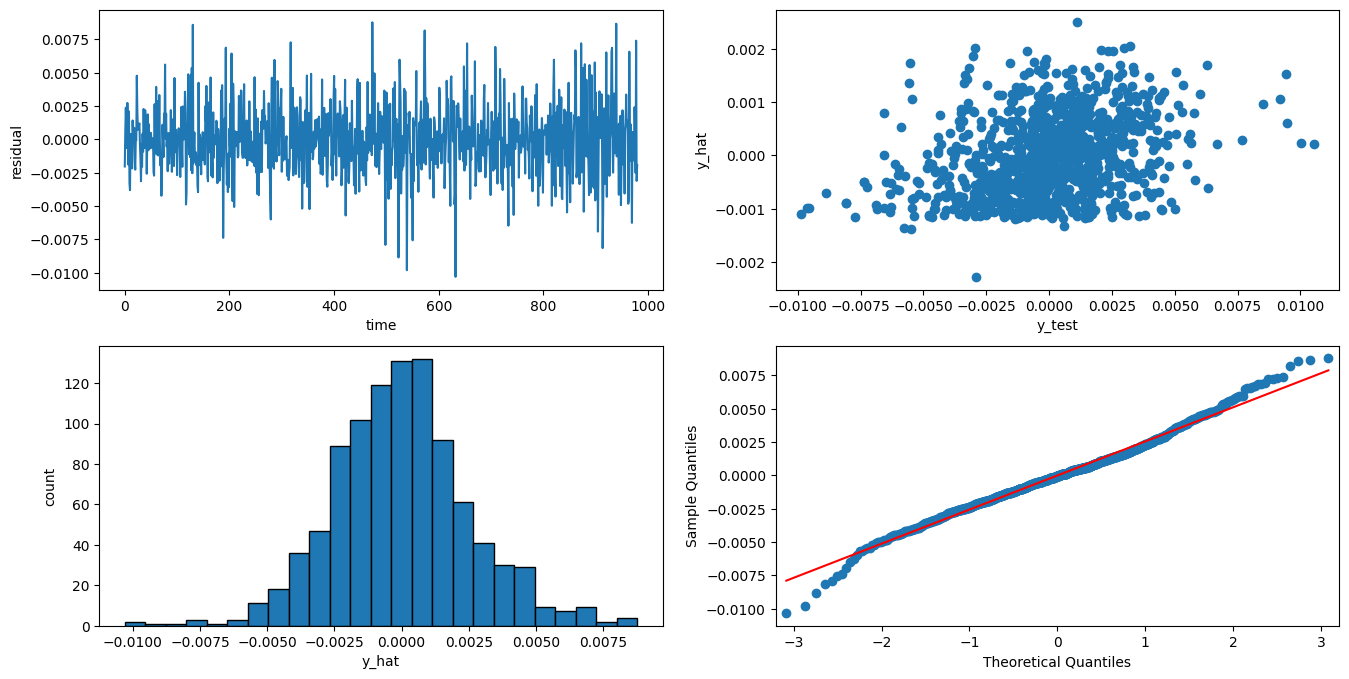

In [10]:
fig, ax = plt.subplots(2, 2, figsize=(16,8))

residuals = y_hat - y_val

ax[0,0].plot(residuals)
ax[0,0].set_xlabel("time")
ax[0,0].set_ylabel("residual")

ax[0,1].scatter(y_val, y_hat)
ax[0,1].set_xlabel("y_test")
ax[0,1].set_ylabel("y_hat")

ax[1,0].hist(residuals, edgecolor='black', bins=25)
ax[1,0].set_xlabel("y_hat")
ax[1,0].set_ylabel("count")

sm.qqplot(residuals.flatten(), line='s', ax=ax[1,1])

plt.show()

In [11]:
import joblib
from sklearn.pipeline import make_pipeline

pipe = make_pipeline(StandardScaler(), Lasso(alpha=1e-4))
pipe.fit(train_data[features].to_numpy(), train_data[target].to_numpy())
joblib.dump(pipe, "forecast_pipe.joblib")

['forecast_pipe.joblib']